# بيان — Voice of Customer Analyzer · المشروع ٣
**Wadeen Khalid Al adwani** · **المدرب: مضر محمد الفضلي** · **أكاديمية سدايا**

تسليم فردي بموافقة المدرب وفق تأكيد المتدربة. الهدف: تصنيف مشاعر التعليقات وتجميع المشكلات وكتابة ملخص قابل للمراجعة. البيانات **198 مثالًا مؤلفًا تعليميًا** وليست بيانات عملاء حقيقيين. الكود والبيانات والتوثيق أُعدت بمساعدة برمجية معلنة.

اختاري Python من `.venv` بعد `bash scripts/run_all.sh`. تعليمات Colab في `GETTING_STARTED.md`. Run all يعيد التدريب والتقييم الحقيقي، ولا يستخدم الاختبار في التدريب. واجهة Gradio موجودة في `app.py`؛ هذا الدفتر يعرض التجربة والنتائج والنسخة الاحتياطية للعرض.

In [1]:
from pathlib import Path
import os, sys, json, subprocess
ROOT = Path.cwd()
if not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
assert (ROOT / "data/feedback.csv").exists(), "Run from the project root or notebooks/"
os.environ.setdefault("MPLCONFIGDIR", "/tmp/bayan-matplotlib")
os.environ.setdefault("XDG_CACHE_HOME", "/workspace/.cache")
sys.path.insert(0, str(ROOT / "src"))
import pandas as pd
from IPython.display import display, Markdown
from bayan.pipeline import load_analyzer
from bayan.text import normalize
data = pd.read_csv(ROOT / "data/feedback.csv")
display(data.groupby(["split", "lang", "label"]).size().rename("n").to_frame())
assert not data.text.map(normalize).duplicated().any()

n
split      lang label       
test       ar   negative  20
                neutral   20
                positive  20
           en   negative   2
                neutral    2
                positive   2
train      ar   negative  30
                neutral   30
                positive  30
           en   negative   4
                neutral    4
                positive   4
validation ar   negative  10
                neutral   10
                positive  10

## ١ — البيانات والخصوصية
إيجابي/سلبي/محايد، فصحى وخليجي وإنجليزي. التقسيم ثابت؛ التطبيع لا يحذف النفي. لا تدخل metadata أو labels إلى الميزات. فحص exact duplicates لا يمنع التشابه الدلالي من مؤلف واحد. `DATA_CARD.md` يشرح حدود الترخيص والتعميم.

In [2]:
from bayan.text import mask_pii
print(mask_pii("مو سيئ، البريد test@example.com والجوال 0501234567"))
display(data[data.split == "test"][["id", "text", "label", "phenomenon"]].head(8))

مو سيئ، البريد [EMAIL] والجوال [PHONE]


,id,text,label,phenomenon
120,VOC-0121,حصلت على مساعدة ممتازة لحل مشكلة الحساب,positive,ordinary
121,VOC-0122,أداء الجهاز رائع بعد شهر من الاستخدام,positive,ordinary
122,VOC-0123,وصلت الشحنة مبكرا وبحالة جيدة,positive,ordinary
123,VOC-0124,قيمة المنتج مناسبة وفاتورته واضحة,positive,ordinary
124,VOC-0125,التطبيق جميل ويسهل متابعة المشتريات,positive,ordinary
125,VOC-0126,لم يتأخر الطلب هذه المرة,positive,negation
126,VOC-0127,ليست الجودة سيئة كما كنت أخشى,positive,negation
127,VOC-0128,لا مشكلة في الدفع بعد الإصلاح,positive,negation


## ٢ — تدريب baseline والتحسين
Baseline: word TF-IDF + Naive Bayes. Improvement: word+character TF-IDF + Logistic Regression؛ C يُختار على validation فقط. التمثيل للتجميع: TF-IDF → SVD 32D → L2، وليس Transformer.

In [3]:
subprocess.run([sys.executable, "scripts/train.py"], cwd=ROOT, check=True)
subprocess.run([sys.executable, "scripts/evaluate.py"], cwd=ROOT, check=True)
training = json.loads((ROOT / "reports/training.json").read_text())
display(pd.DataFrame(training["candidates"]))

{
  "seed": 42,
  "train_n": 102,
  "validation_n": 30,
  "selection": "Highest validation macro-F1; first candidate wins ties. No train+validation refit.",
  "candidates": [
    {
      "C": 0.5,
      "validation_macro_f1": 0.6018518518518519
    },
    {
      "C": 2.0,
      "validation_macro_f1": 0.6018518518518519
    },
    {
      "C": 8.0,
      "validation_macro_f1": 0.6018518518518519
    }
  ],
  "selected_C": 0.5,
  "data_sha256": "1590fcc1c0659e9f29e0e067d5d11cace10932e4bb9facff3d4a39e20588271b",
  "svd_explained_variance": 0.47291556304256555
}


{
  "metrics": {
    "baseline": {
      "n": 66,
      "accuracy": 0.5303030303030303,
      "macro_f1": 0.532536266539136,
      "macro_f1_95ci": [
        0.4022092192724637,
        0.6561365593923733
      ],
      "confusion_matrix_labels": [
        "negative",
        "neutral",
        "positive"
      ],
      "confusion_matrix": [
        [
          13,
          4,
          5
        ],
        [
          6,
          12,
          4
        ],
        [
          10,
          2,
          10
        ]
      ]
    },
    "improved": {
      "n": 66,
      "accuracy": 0.5757575757575758,
      "macro_f1": 0.5748917748917749,
      "macro_f1_95ci": [
        0.4396962181031457,
        0.7051887668434799
      ],
      "confusion_matrix_labels": [
        "negative",
        "neutral",
        "positive"
      ],
      "confusion_matrix": [
        [
          16,
          2,
          4
        ],
        [
          8,
          10,
          4
        ],
        [
   

,C,validation_macro_f1
0,0.5,0.601852
1,2.0,0.601852
2,8.0,0.601852


## ٣ — نفس الاختبار لكل نموذج
قياس فعلي، فواصل bootstrap 95% وpaired difference. لا ندعي تفوقًا عامًا إذا شمل فاصل الفرق الصفر.

In [4]:
metrics = json.loads((ROOT / "reports/metrics.json").read_text())
display(pd.DataFrame({name: metrics[name] for name in ["baseline", "improved"]}).T[["n", "accuracy", "macro_f1", "macro_f1_95ci"]])
print("Paired delta:", metrics["paired_delta"])
display(pd.read_csv(ROOT / "reports/slices.csv"))
display(metrics["review_policy"])

,n,accuracy,macro_f1,macro_f1_95ci
baseline,66,0.530303,0.532536,"[0.4022092192724637, 0.6561365593923733]"
improved,66,0.575758,0.574892,"[0.4396962181031457, 0.7051887668434799]"


Paired delta: {'macro_f1': 0.042355508352638904, '95ci': [-0.03202698936778443, 0.1279886405761241], 'note': 'Exploratory bootstrap on a small synthetic test set, not population-level evidence.'}


,system,slice,n,accuracy,macro_f1
0,baseline,lang=ar,60,0.550000,0.551106
1,baseline,lang=en,6,0.333333,0.266667
2,baseline,dialect=english,6,0.333333,0.266667
3,baseline,dialect=gulf,30,0.700000,0.701010
4,baseline,dialect=msa,30,0.400000,0.380556
5,baseline,phenomenon=dialect,4,0.500000,0.266667
6,baseline,phenomenon=insufficient_evidence,4,0.250000,0.133333
7,baseline,phenomenon=mixed,5,0.400000,0.300000
8,baseline,phenomenon=negation,7,0.142857,0.083333
9,baseline,phenomenon=ordinary,33,0.696970,0.699415


{'threshold': 0.55,
 'coverage': 0.0,
 'accepted_n': 0,
 'review_n': 66,
 'accepted_macro_f1': None,
 'note': 'Confidence is uncalibrated; 0.55 is a demo routing heuristic, not a tuned reliability guarantee.'}

## ٤ — أخطاء فعلية وليس أمثلة نجاح مختارة
كل خطأ في CSV له ID وتعليق وتسميات وسبب محتمل وخطوة علاج. التصنيف التشخيصي للسبب ليس مراجعة مستقلة من خبير.

In [5]:
errors = pd.read_csv(ROOT / "reports/error_analysis.csv")
assert len(errors) >= 10 and (errors.label != errors.improved_pred).all()
display(errors.groupby("error_category").size().rename("failures").to_frame())
display(errors[["id", "text", "label", "improved_pred", "error_category"]].head(15))

,failures
error_category,
dialect_or_idiom,2
insufficient_evidence,3
lexical_generalization,9
mixed_sentiment,2
negation,5
quoted_or_questioned_sentiment,6
sarcasm,1


,id,text,label,improved_pred,error_category
0,VOC-0121,حصلت على مساعدة ممتازة لحل مشكلة الحساب,positive,negative,lexical_generalization
1,VOC-0122,أداء الجهاز رائع بعد شهر من الاستخدام,positive,neutral,lexical_generalization
2,VOC-0123,وصلت الشحنة مبكرا وبحالة جيدة,positive,negative,lexical_generalization
3,VOC-0125,التطبيق جميل ويسهل متابعة المشتريات,positive,negative,lexical_generalization
4,VOC-0126,لم يتأخر الطلب هذه المرة,positive,negative,negation
5,VOC-0127,ليست الجودة سيئة كما كنت أخشى,positive,negative,negation
6,VOC-0129,السعر مرتفع لكن المنتج يستحق كل ريال,positive,negative,mixed_sentiment
7,VOC-0134,التطبيق سهل وواضح ويختصر الوقت,positive,negative,lexical_generalization
8,VOC-0138,مو غالي إذا شفت جودته,positive,negative,negation
9,VOC-0144,الدعم تجاهل المشكلة ولم يساعدني,negative,positive,lexical_generalization


## ٥ — demo: تصنيف + embeddings + clustering + summary
يمكن تعديل قائمة التعليقات أدناه وإعادة تشغيل الخلية. المخرجات المحلية لا تتصل بـAPI. الملخص يعد التنبؤات ويعرض تعليقًا ممثلًا؛ أسماء المواضيع بقواعد وتحتاج مراجعة.

In [6]:
comments = pd.read_csv(ROOT / "sample_outputs/demo_input.csv").text.tolist()
analyzer = load_analyzer()
result = analyzer.analyze(comments)
assert result["total"] == len(comments)
assert sum(c["size"] for c in result["clusters"]) == len(comments)
display(pd.DataFrame(result["predictions"]))
display(pd.DataFrame(result["clusters"]))
for cluster in result["clusters"]:
    print(cluster["summary"])
    print("شاهد:", cluster["representative"])
print("Embedding shape:", analyzer.embed(comments).shape)

,text,sentiment,sentiment_ar,confidence,needs_review,aspect
0,حصلت على مساعدة ممتازة لحل مشكلة الحساب,negative,سلبي,0.4293,True,التطبيق والدفع
1,أداء الجهاز رائع بعد شهر من الاستخدام,neutral,محايد,0.3745,True,الجودة
2,وصلت الشحنة مبكرا وبحالة جيدة,negative,سلبي,0.3814,True,التوصيل
3,قيمة المنتج مناسبة وفاتورته واضحة,positive,إيجابي,0.4514,True,السعر
4,التطبيق جميل ويسهل متابعة المشتريات,negative,سلبي,0.3652,True,التطبيق والدفع
5,تعطلت عملية الدفع وخسرت وقتي,negative,سلبي,0.3630,True,التطبيق والدفع
6,التوصيل بطيء والمندوب لم يحضر,negative,سلبي,0.4280,True,التوصيل
7,الجهاز سيئ ولا يطابق الإعلان,negative,سلبي,0.3675,True,الجودة
8,الدعم تجاهل المشكلة ولم يساعدني,positive,إيجابي,0.3868,True,الدعم والاسترجاع
9,رسوم إضافية مرتفعة لم تذكر في الفاتورة,negative,سلبي,0.3439,True,السعر


,cluster,size,topic,sentiment_counts,representative,summary
0,0,4,الجودة,"{'neutral': 3, 'negative': 1}",أداء الجهاز رائع بعد شهر من الاستخدام,مجموعة الجودة: 4 تعليقًا، منها 1 سلبي، و0 إيجا...
1,1,3,التطبيق والدفع,"{'negative': 2, 'positive': 1}",الدعم تجاهل المشكلة ولم يساعدني,مجموعة التطبيق والدفع: 3 تعليقًا، منها 2 سلبي،...
2,2,4,السعر,"{'positive': 2, 'negative': 2}",قيمة المنتج مناسبة وفاتورته واضحة,مجموعة السعر: 4 تعليقًا، منها 2 سلبي، و2 إيجاب...
3,3,2,التوصيل,"{'negative': 1, 'neutral': 1}",التوصيل بطيء والمندوب لم يحضر,مجموعة التوصيل: 2 تعليقًا، منها 1 سلبي، و0 إيج...
4,4,2,التوصيل,"{'negative': 1, 'neutral': 1}",كيف أستطيع تفعيل إشعارات الطلب,مجموعة التوصيل: 2 تعليقًا، منها 1 سلبي، و0 إيج...


مجموعة الجودة: 4 تعليقًا، منها 1 سلبي، و0 إيجابي، و3 محايد. الأعداد مبنية على تنبؤات النموذج وتحتاج مراجعة بشرية.
شاهد: أداء الجهاز رائع بعد شهر من الاستخدام
مجموعة التطبيق والدفع: 3 تعليقًا، منها 2 سلبي، و1 إيجابي، و0 محايد. الأعداد مبنية على تنبؤات النموذج وتحتاج مراجعة بشرية.
شاهد: الدعم تجاهل المشكلة ولم يساعدني
مجموعة السعر: 4 تعليقًا، منها 2 سلبي، و2 إيجابي، و0 محايد. الأعداد مبنية على تنبؤات النموذج وتحتاج مراجعة بشرية.
شاهد: قيمة المنتج مناسبة وفاتورته واضحة
مجموعة التوصيل: 2 تعليقًا، منها 1 سلبي، و0 إيجابي، و1 محايد. الأعداد مبنية على تنبؤات النموذج وتحتاج مراجعة بشرية.
شاهد: التوصيل بطيء والمندوب لم يحضر
مجموعة التوصيل: 2 تعليقًا، منها 1 سلبي، و0 إيجابي، و1 محايد. الأعداد مبنية على تنبؤات النموذج وتحتاج مراجعة بشرية.
شاهد: كيف أستطيع تفعيل إشعارات الطلب
Embedding shape: (15, 32)


## ٦ — قرار عدم fine-tuning
الدورة تسمح بالتبرير المدعوم بالأدلة. البيانات المؤلفة صغيرة، ولا توجد مراجعة تسمية مستقلة، ومنحنى التعلم غير رتيب، وفرق الاختبار غير محسوم. التدريب الخطي ليس fine-tuning لمحول. لم نختبر Transformer؛ لا ندعي أن الأداء سيكون أسوأ. التالي: بيانات حقيقية مصرح بها ثم مقارنة encoder/fine-tuning على اختبار جديد. انظري `DECISIONS.md`.

,train_n,fit_seconds,validation_macro_f1
0,25,0.009929,0.477778
1,51,0.013283,0.487499
2,76,0.018394,0.629630
3,102,0.024001,0.601852


{'python': '3.12.14',
 'platform': 'Linux-6.18.44-x86_64-with-glibc2.41',
 'logical_cpus': 5,
 'batch_size': 1,
 'warmup': 5,
 'repeats': 66,
 'api_cost_per_1000_usd': 0.0,
 'cost_scope': 'No API calls; excludes CPU, electricity and hosting.',
 'baseline': {'p50_ms': 0.5384000000958622, 'p95_ms': 0.6859309999072138},
 'improved': {'p50_ms': 1.3049095002770628, 'p95_ms': 1.4489437500060376}}

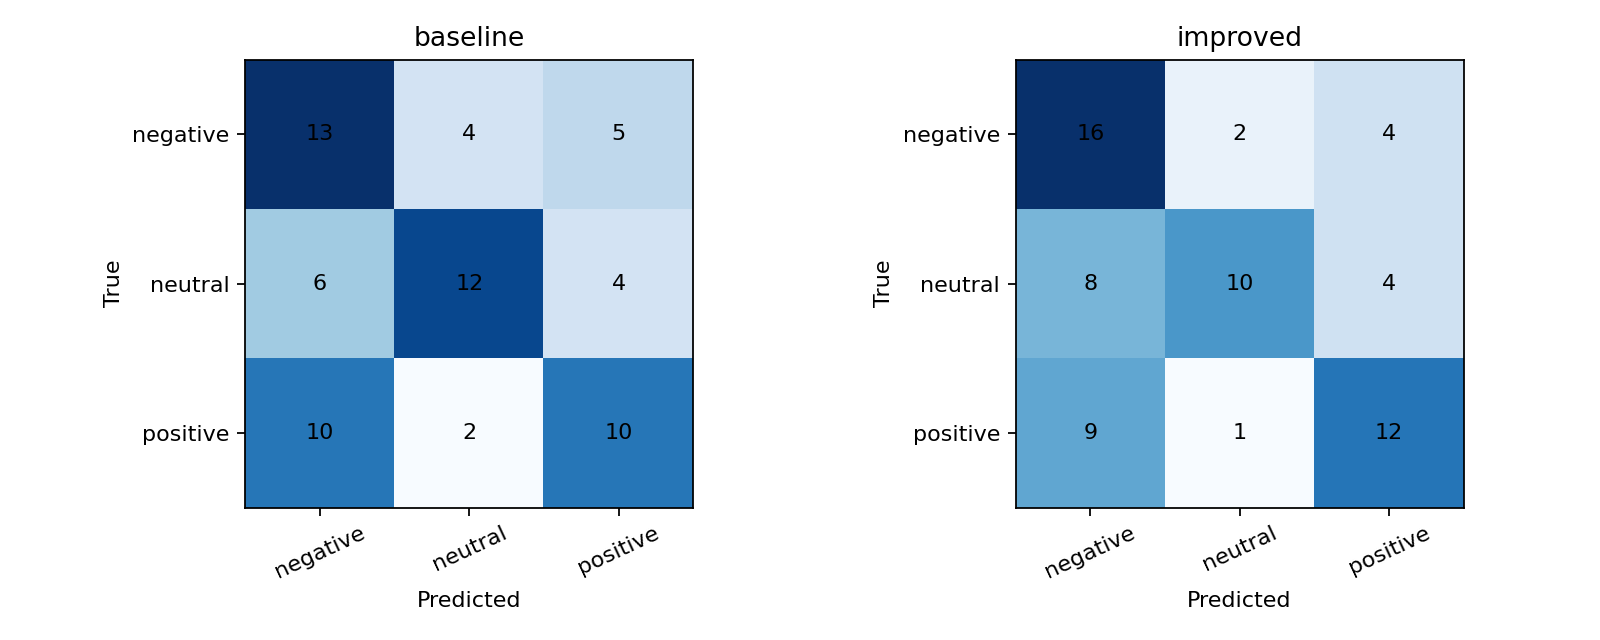

In [7]:
display(pd.read_csv(ROOT / "reports/learning_curve.csv"))
display(json.loads((ROOT / "reports/benchmark.json").read_text()))
from IPython.display import Image
display(Image(filename=str(ROOT / "reports/confusion_matrices.png")))

## ٧ — تشغيل الواجهة والعرض
في terminal: `uv run --frozen python app.py`. اعرضي مثالًا إيجابيًا وآخر سلبيًا وسؤالًا محايدًا ثم CSV. خلايا هذا الدفتر و`sample_outputs/analysis.json` نسخة احتياطية قابلة للفحص، وليست فيديو مسجلًا. `PRESENTATION.md` ثماني شرائح وشرح لعشر دقائق. راجعي وفهمي الكود والحدود قبل التسليم.

لا توجد موافقة قبول أو تقديم عرض تلقائي. المتدربة أكدت إذن التسليم الفردي. سياسة الاستعانة بالمساعد البرمجي يجب مراعاتها.